<h1 style="color:darkblue; font-weight:bold; font-size:40px;">
Loan Application EDA
</h1>


In [393]:
# Importing Python Packages
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import numpy as np
import os

from sklearn.linear_model import Lasso

from sklearn.feature_selection import VarianceThreshold
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import LabelEncoder, StandardScaler, MinMaxScaler, RobustScaler

from sklearn.metrics import explained_variance_score, mean_squared_log_error, median_absolute_error, max_error

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.utils.class_weight import compute_sample_weight


# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")


In [198]:
# Reading transaction dataset
dataset_path = r"H:\Documents\Bigdata_course\fraud_loan\transactions.csv"

tran_df = pd.read_csv(dataset_path ,sep=',')

# Displaying the dataset
tran_df.head()

,transaction_id,customer_id,transaction_date,transaction_type,transaction_amount,merchant_category,merchant_name,transaction_location,account_balance_after_transaction,is_international_transaction,device_used,ip_address,transaction_status,transaction_source_destination,transaction_notes,fraud_flag
0,2d7ddfd4-1112-4354-a2dd-fad94b45a850,CUST102188,2022-01-04 11:27:00,Bill Payment,2100.0,Dining,"Rattan, Khanna and Magar","Srikakulam, Himachal Pradesh",8211.0,0,Web,31.102.21.141,Success,BCHG80012468703731,Payment for Dining,0
1,ba998721-a612-4e0a-8354-46d001e9c39c,CUST107144,2022-01-03 23:52:00,UPI,1400.0,Travel,Chauhan LLC,"Giridih, Manipur",12858.0,0,Web,176.48.222.166,Success,CJPZ11841095072972,Payment for Travel,0
2,0b4ad8e2-40ac-49c9-b59a-c9efaaccc7a6,CUST102126,2022-01-15 06:54:00,Debit Card,1000.0,Entertainment,Halder-Sarma,"Avadi, Kerala",19268.0,0,ATM,181.62.105.161,Success,TLCG50761416960179,Payment for Entertainment,0
3,c4fce988-34c5-48db-8686-bfad0b3bc0b5,CUST109887,2022-01-08 07:57:00,Credit Card,10500.0,Utilities,"Anand, Khare and Balakrishnan","Navi Mumbai, Maharashtra",29585.0,0,ATM,121.157.246.80,Success,PRZJ55096553432036,Payment for Utilities,0
4,f9b8ca30-00e5-4322-8cff-eac0554cf2da,CUST108620,2022-01-02 10:43:00,Loan Disbursement,8100.0,Electronics,Zacharia and Sons,"Visakhapatnam, Gujarat",0.0,0,ATM,129.96.5.57,Success,NBAI29021393288369,Payment for Electronics,0


In [199]:
# Reading loan application dataset
dataset_path = r"H:\Documents\Bigdata_course\fraud_loan\loan_applications.csv"

loan_df = pd.read_csv(dataset_path ,sep=',')

# Displaying the dataset
loan_df.head()

,application_id,customer_id,application_date,loan_type,loan_amount_requested,loan_tenure_months,interest_rate_offered,purpose_of_loan,employment_status,monthly_income,...,existing_emis_monthly,debt_to_income_ratio,property_ownership_status,residential_address,applicant_age,gender,number_of_dependents,loan_status,fraud_flag,fraud_type
0,c8bf0bea-70e6-4870-9125-41b8210c527f,CUST109427,2023-04-09,Business Loan,604000.0,12,11.66,Medical Emergency,Retired,34700.0,...,1100.0,3.17,Rented,"94/31, Sehgal Zila, Vadodara-380521, Anantapur...",28,Female,3,Approved,0,NaN
1,91224cec-3544-4bc7-ac15-a9792da54c02,CUST106146,2023-09-23,Car Loan,100000.0,240,13.62,Education,Unemployed,51600.0,...,0.0,0.00,Owned,"H.No. 00, Sheth Chowk, Ichalkaranji 006728, Im...",44,Other,3,Approved,0,NaN
2,4efcd02d-4a03-4ab7-9bd1-0ff430493d0c,CUST100674,2023-05-22,Education Loan,431000.0,60,11.40,Medical Emergency,Self-Employed,14800.0,...,4600.0,31.08,Rented,"H.No. 81, Dutta Path, Kozhikode-340301, Tadepa...",56,Other,4,Approved,0,NaN
3,a61337d4-ba04-4a68-b492-2cb8266e6ed7,CUST106466,2024-07-09,Car Loan,324000.0,120,10.36,Debt Consolidation,Self-Employed,28800.0,...,4000.0,13.89,Rented,"H.No. 022, Rege Road, Tiruvottiyur-927857, Aur...",27,Other,4,Declined,0,NaN
4,a8d1639e-170b-41b2-826a-55c7dae38d16,CUST112319,2023-11-20,Personal Loan,100000.0,36,14.14,Business Expansion,Salaried,43900.0,...,1100.0,2.51,Rented,"85/24, Bali Zila, Sambalpur 922071, Tumkur, Ke...",50,Other,0,Declined,0,NaN


In [200]:
#merging the datasets with columns of both the dataset present

merged_df = pd.merge(tran_df, loan_df, on='customer_id', how='outer')

#display the data

merged_df.head()

,transaction_id,customer_id,transaction_date,transaction_type,transaction_amount,merchant_category,merchant_name,transaction_location,account_balance_after_transaction,is_international_transaction,...,existing_emis_monthly,debt_to_income_ratio,property_ownership_status,residential_address,applicant_age,gender,number_of_dependents,loan_status,fraud_flag_y,fraud_type
0,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,2000.0,3.21,Jointly Owned,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN
1,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,2000.0,3.21,Rented,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN
2,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,2500.0,4.01,Rented,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN
3,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,3500.0,5.61,Owned,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN
4,ee57f580-a235-48b8-a562-bdfc09061af4,CUST100000,2022-01-20 15:33:00,Credit Card,2500.0,Electronics,"Viswanathan, Subramaniam and Kashyap","Howrah, Mizoram",0.0,0.0,...,1300.0,2.08,Owned,"321, Bassi Circle, Patna 133890, Bongaigaon, M...",61.0,Male,2.0,Approved,0.0,NaN


In [201]:
# Dataset inforamtion
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133725 entries, 0 to 133724
Data columns (total 36 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   transaction_id                     129522 non-null  object 
 1   customer_id                        133725 non-null  object 
 2   transaction_date                   129522 non-null  object 
 3   transaction_type                   129522 non-null  object 
 4   transaction_amount                 129522 non-null  float64
 5   merchant_category                  129522 non-null  object 
 6   merchant_name                      129522 non-null  object 
 7   transaction_location               129522 non-null  object 
 8   account_balance_after_transaction  129522 non-null  float64
 9   is_international_transaction       129522 non-null  float64
 10  device_used                        129522 non-null  object 
 11  ip_address                         1295

In [202]:
#selecting some columns

merged_df.loc[152:162, ["fraud_type", "fraud_flag_y", "fraud_flag_x"]] 


,fraud_type,fraud_flag_y,fraud_flag_x
152,Transaction Laundering,1.0,0.0
153,Transaction Laundering,1.0,0.0
154,Synthetic Identity,1.0,0.0
155,Transaction Laundering,1.0,1.0
156,Transaction Laundering,1.0,1.0
157,Synthetic Identity,1.0,1.0
158,Transaction Laundering,1.0,0.0
159,Transaction Laundering,1.0,0.0
160,Synthetic Identity,1.0,0.0
161,Transaction Laundering,1.0,0.0


In [204]:
#checking data of fraud  

fr = merged_df[merged_df['fraud_flag_x'] >= 1]
fr.head()

,transaction_id,customer_id,transaction_date,transaction_type,transaction_amount,merchant_category,merchant_name,transaction_location,account_balance_after_transaction,is_international_transaction,...,existing_emis_monthly,debt_to_income_ratio,property_ownership_status,residential_address,applicant_age,gender,number_of_dependents,loan_status,fraud_flag_y,fraud_type
155,bbd0c077-54f9-4c38-9d92-cdc2fe5fba36,CUST100032,2022-01-02 14:13:00,Fund Transfer,4400.000000,Travel,Sastry and Sons,"Danapur, Madhya Pradesh",37777.00,0.0,...,2700.0,5.43,Rented,"H.No. 385, Shukla, Mango-348247, Bhilai, Andhr...",35.0,Male,3.0,Fraudulent - Detected,1.0,Transaction Laundering
156,bbd0c077-54f9-4c38-9d92-cdc2fe5fba36,CUST100032,2022-01-02 14:13:00,Fund Transfer,4400.000000,Travel,Sastry and Sons,"Danapur, Madhya Pradesh",37777.00,0.0,...,4300.0,8.65,Owned,"H.No. 385, Shukla, Mango-348247, Bhilai, Andhr...",35.0,Male,3.0,Fraudulent - Undetected,1.0,Transaction Laundering
157,bbd0c077-54f9-4c38-9d92-cdc2fe5fba36,CUST100032,2022-01-02 14:13:00,Fund Transfer,4400.000000,Travel,Sastry and Sons,"Danapur, Madhya Pradesh",37777.00,0.0,...,5900.0,11.87,Owned,"H.No. 385, Shukla, Mango-348247, Bhilai, Andhr...",35.0,Male,3.0,Fraudulent - Undetected,1.0,Synthetic Identity
164,f51227fe-25fe-42c4-9132-0d2efd869130,CUST100032,2022-01-08 10:51:00,Debit Card,1936.414585,Entertainment,Rout and Sons,"Guntur, Assam",17219.59,0.0,...,2700.0,5.43,Rented,"H.No. 385, Shukla, Mango-348247, Bhilai, Andhr...",35.0,Male,3.0,Fraudulent - Detected,1.0,Transaction Laundering
165,f51227fe-25fe-42c4-9132-0d2efd869130,CUST100032,2022-01-08 10:51:00,Debit Card,1936.414585,Entertainment,Rout and Sons,"Guntur, Assam",17219.59,0.0,...,4300.0,8.65,Owned,"H.No. 385, Shukla, Mango-348247, Bhilai, Andhr...",35.0,Male,3.0,Fraudulent - Undetected,1.0,Transaction Laundering


In [205]:
# Dataset inforamtion
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 133725 entries, 0 to 133724
Data columns (total 36 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   transaction_id                     129522 non-null  object 
 1   customer_id                        133725 non-null  object 
 2   transaction_date                   129522 non-null  object 
 3   transaction_type                   129522 non-null  object 
 4   transaction_amount                 129522 non-null  float64
 5   merchant_category                  129522 non-null  object 
 6   merchant_name                      129522 non-null  object 
 7   transaction_location               129522 non-null  object 
 8   account_balance_after_transaction  129522 non-null  float64
 9   is_international_transaction       129522 non-null  float64
 10  device_used                        129522 non-null  object 
 11  ip_address                         1295

In [206]:
# Display statistical summary of numerical columns
merged_df.describe()

,transaction_amount,account_balance_after_transaction,is_international_transaction,fraud_flag_x,loan_amount_requested,loan_tenure_months,interest_rate_offered,monthly_income,cibil_score,existing_emis_monthly,debt_to_income_ratio,applicant_age,number_of_dependents,fraud_flag_y
count,129522.000000,129522.000000,129522.000000,129522.000000,1.294840e+05,129484.000000,129484.000000,129484.000000,129484.000000,129484.000000,129484.000000,129484.000000,129484.000000,129484.000000
mean,4985.180421,21902.939354,0.009998,0.010199,5.143832e+05,121.455655,10.527164,50805.996880,699.022929,3069.352198,8.581861,43.109326,2.007661,0.020906
std,5058.433509,14632.170410,0.099491,0.100474,2.762858e+05,121.490686,1.924321,23805.173569,49.766513,1893.455229,9.554791,13.019074,1.404444,0.143070
min,100.000000,0.000000,0.000000,0.000000,1.000000e+05,12.000000,7.000000,10000.000000,476.000000,0.000000,0.000000,21.000000,0.000000,0.000000
25%,1400.000000,9209.000000,0.000000,0.000000,3.000000e+05,24.000000,9.160000,33600.000000,665.000000,1700.000000,3.120000,32.000000,1.000000,0.000000
50%,3400.000000,21506.500000,0.000000,0.000000,5.030000e+05,60.000000,10.510000,50300.000000,699.000000,3000.000000,5.950000,43.000000,2.000000,0.000000
75%,6900.000000,33958.000000,0.000000,0.000000,7.020000e+05,240.000000,11.840000,67300.000000,733.000000,4400.000000,10.340000,54.000000,3.000000,0.000000
max,76531.610223,89097.000000,1.000000,1.000000,1.618000e+06,360.000000,19.620000,162000.000000,888.000000,11400.000000,102.000000,65.000000,4.000000,1.000000


In [207]:
# Count the occurrences of 'nan'
nan_count = merged_df.isna().sum()

# Display the count of 'nan' values per column
print("\nCount of 'nan' as string values per column:")
print(nan_count)


Count of 'nan' as string values per column:
transaction_id                         4203
customer_id                               0
transaction_date                       4203
transaction_type                       4203
transaction_amount                     4203
merchant_category                      4203
merchant_name                          4203
transaction_location                   4203
account_balance_after_transaction      4203
is_international_transaction           4203
device_used                            4203
ip_address                             4203
transaction_status                     4203
transaction_source_destination         4203
transaction_notes                      4203
fraud_flag_x                           4203
application_id                         4241
application_date                       4241
loan_type                              4241
loan_amount_requested                  4241
loan_tenure_months                     4241
interest_rate_offered          

In [208]:
# datetypes of columns
merged_df.dtypes

transaction_id                        object
customer_id                           object
transaction_date                      object
transaction_type                      object
transaction_amount                   float64
merchant_category                     object
merchant_name                         object
transaction_location                  object
account_balance_after_transaction    float64
is_international_transaction         float64
device_used                           object
ip_address                            object
transaction_status                    object
transaction_source_destination        object
transaction_notes                     object
fraud_flag_x                         float64
application_id                        object
application_date                      object
loan_type                             object
loan_amount_requested                float64
loan_tenure_months                   float64
interest_rate_offered                float64
purpose_of

In [209]:
# Count of columns
num_columns = len(merged_df.columns)

# Identify numerical int, float and categorical columns
numerical_int_columns = merged_df.select_dtypes(include=['int32', 'int64']).columns
numerical_float_columns = merged_df.select_dtypes(include=[ 'float32', 'float64']).columns
categorical_columns = merged_df.select_dtypes(include='object').columns
boolean_columns = merged_df.select_dtypes(include='bool').columns

# Display information
print(f"Total columns: {num_columns}")

if len(numerical_int_columns) > 0:
    print(f"\nNumerical integer columns ({len(numerical_int_columns)}): {', '.join(numerical_int_columns)}")
else:
    print(f"\nNo numerical integer columns found.")

if len(numerical_float_columns) > 0:
    print(f"\nNumerical float columns ({len(numerical_float_columns)}): {', '.join(numerical_float_columns)}")
else:
    print(f"\nNo numerical float columns found.")

if len(categorical_columns) > 0:
    print(f"\nCategorical columns ({len(categorical_columns)}): {', '.join(categorical_columns)}")
else:
    print(f"\nNo categorical columns found.")

if len(boolean_columns) > 0:
    print(f"\nBoolean columns ({len(boolean_columns)}): {', '.join(boolean_columns)}")
else:
    print(f"\nNo Boolean columns found.")

Total columns: 36

No numerical integer columns found.

Numerical float columns (14): transaction_amount, account_balance_after_transaction, is_international_transaction, fraud_flag_x, loan_amount_requested, loan_tenure_months, interest_rate_offered, monthly_income, cibil_score, existing_emis_monthly, debt_to_income_ratio, applicant_age, number_of_dependents, fraud_flag_y

Categorical columns (22): transaction_id, customer_id, transaction_date, transaction_type, merchant_category, merchant_name, transaction_location, device_used, ip_address, transaction_status, transaction_source_destination, transaction_notes, application_id, application_date, loan_type, purpose_of_loan, employment_status, property_ownership_status, residential_address, gender, loan_status, fraud_type

No Boolean columns found.


In [210]:
# Count unique values for each column
unique_counts = merged_df.nunique()

# Display the count of unique values for each column
print("Count of Unique Values for Each Column:")
print(unique_counts)

Count of Unique Values for Each Column:
transaction_id                       50000
customer_id                          19866
transaction_date                     30012
transaction_type                        10
transaction_amount                     639
merchant_category                       12
merchant_name                        35312
transaction_location                  8823
account_balance_after_transaction    30267
is_international_transaction             2
device_used                              4
ip_address                           50000
transaction_status                       2
transaction_source_destination       39993
transaction_notes                       12
fraud_flag_x                             2
application_id                       50000
application_date                      1096
loan_type                                5
loan_amount_requested                 1312
loan_tenure_months                       7
interest_rate_offered                  983
purpose_of_loa

<h1 style="color:darkblue; font-weight:bold; font-size:40px;">
Data Visualization
</h1>


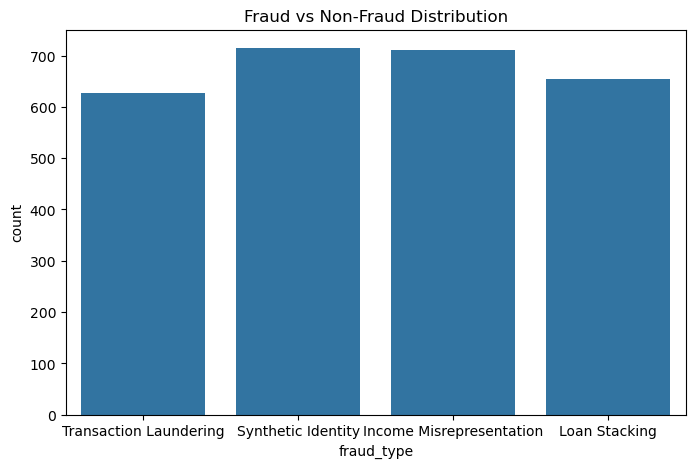

In [67]:
#1.'Fraud vs Non-Fraud Distribution'

plt.figure(figsize=(8, 5))
sns.countplot(x='fraud_type', data=merged_df)
plt.title('Fraud vs Non-Fraud Distribution')
plt.show()


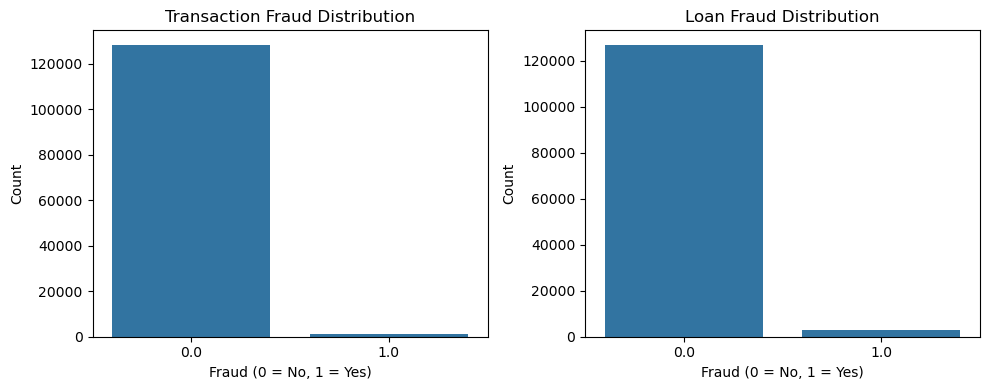

In [68]:
#2 Overall Fraud count in transaction and loan application

plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.countplot(x='fraud_flag_x', data=merged_df)
plt.title('Transaction Fraud Distribution')
plt.xlabel('Fraud (0 = No, 1 = Yes)')
plt.ylabel('Count')

plt.subplot(1,2,2)
sns.countplot(x='fraud_flag_y', data=merged_df)
plt.title('Loan Fraud Distribution')
plt.xlabel('Fraud (0 = No, 1 = Yes)')
plt.ylabel('Count')

plt.tight_layout()
plt.show()


##  Bivariate Analysis

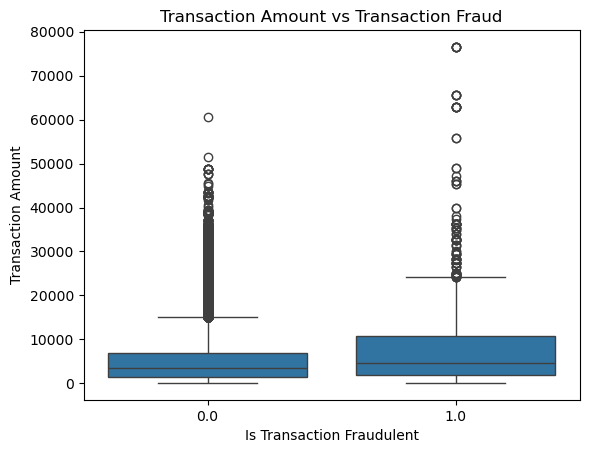

In [70]:
#3 Fraud vs Transaction Amount

sns.boxplot(x='fraud_flag_x', y='transaction_amount', data=merged_df)
plt.title('Transaction Amount vs Transaction Fraud')
plt.xlabel('Is Transaction Fraudulent')
plt.ylabel('Transaction Amount')
plt.show()


In [71]:
#the fig shows that the fraud amounts are higher than normal transactions

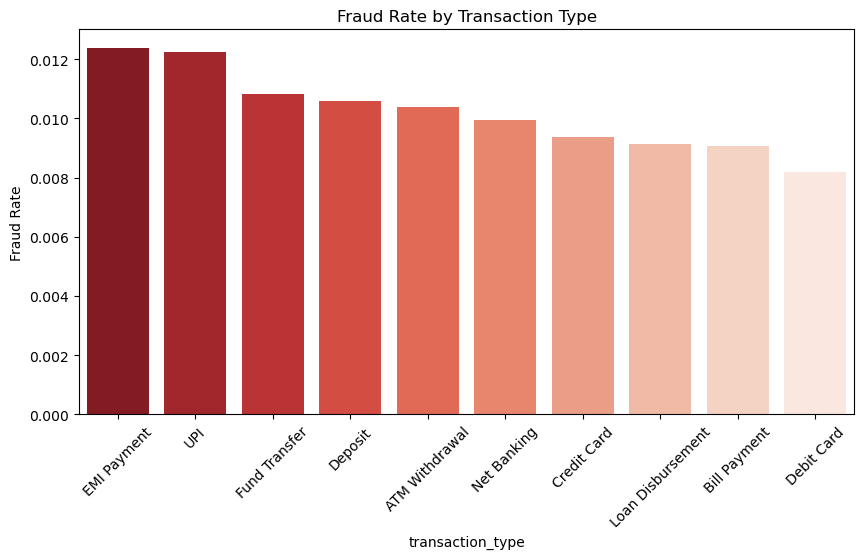

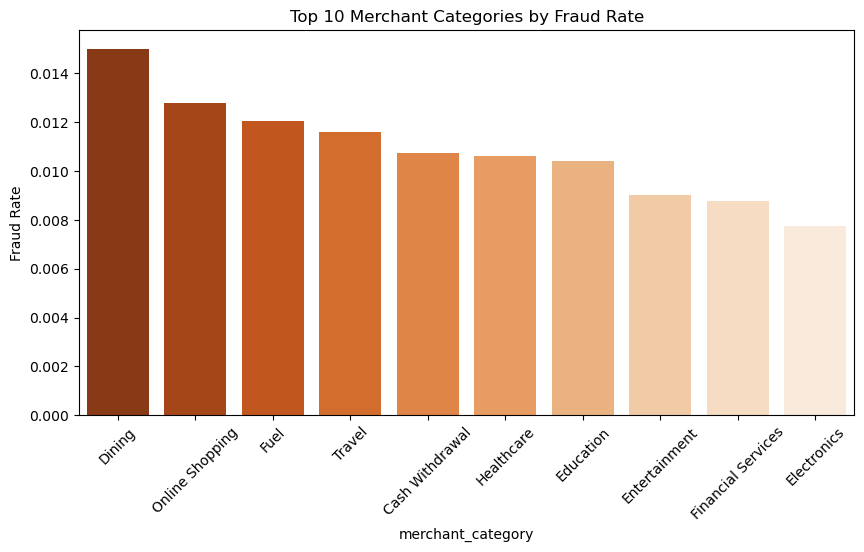

In [72]:
#4 Fraud by Transaction Type or Merchant Category

plt.figure(figsize=(10,5))
fraud_rate = merged_df.groupby('transaction_type')['fraud_flag_x'].mean().sort_values(ascending=False)
sns.barplot(x=fraud_rate.index, y=fraud_rate.values, palette='Reds_r')
plt.xticks(rotation=45)
plt.title('Fraud Rate by Transaction Type')
plt.ylabel('Fraud Rate')
plt.show()

#5
plt.figure(figsize=(10,5))
fraud_rate = merged_df.groupby('merchant_category')['fraud_flag_x'].mean().sort_values(ascending=False).head(10)
sns.barplot(x=fraud_rate.index, y=fraud_rate.values, palette='Oranges_r')
plt.xticks(rotation=45)
plt.title('Top 10 Merchant Categories by Fraud Rate')
plt.ylabel('Fraud Rate')
plt.show()



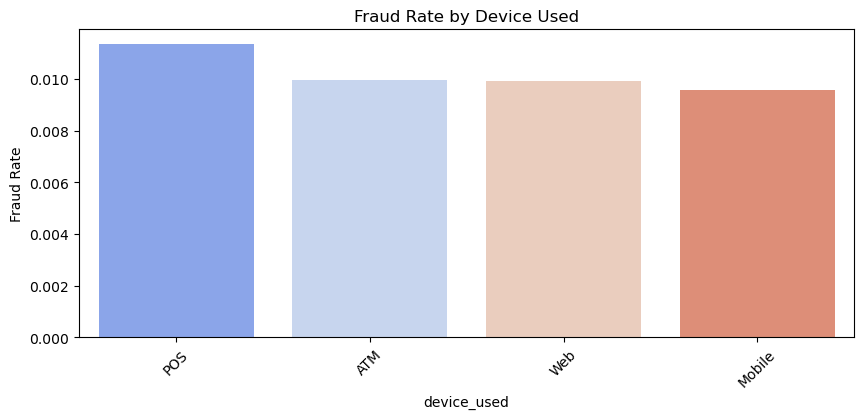

In [73]:
#6 Device and Channel Analysis

plt.figure(figsize=(10,4))
fraud_rate = merged_df.groupby('device_used')['fraud_flag_x'].mean().sort_values(ascending=False)
sns.barplot(x=fraud_rate.index, y=fraud_rate.values, palette='coolwarm')
plt.xticks(rotation=45)
plt.title('Fraud Rate by Device Used')
plt.ylabel('Fraud Rate')
plt.show()


In [74]:
# thus POS has higher fraud probability

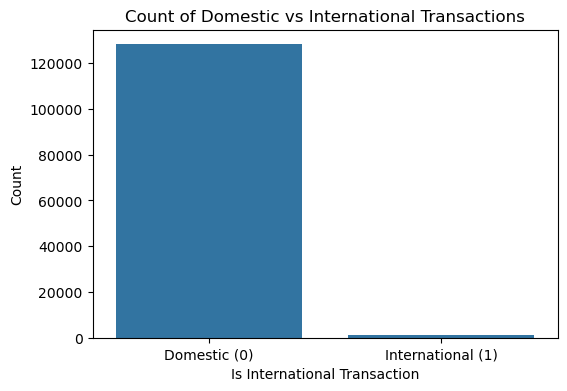

In [75]:
#7 Count plot (distribution of domestic vs international transactions)#

plt.figure(figsize=(6,4))
sns.countplot(x='is_international_transaction', data=merged_df)
plt.title('Count of Domestic vs International Transactions')
plt.xlabel('Is International Transaction')
plt.ylabel('Count')
plt.xticks([0,1], ['Domestic (0)', 'International (1)'])
plt.show()

In [76]:
#therefore most of the transaction fraud takes place domestically

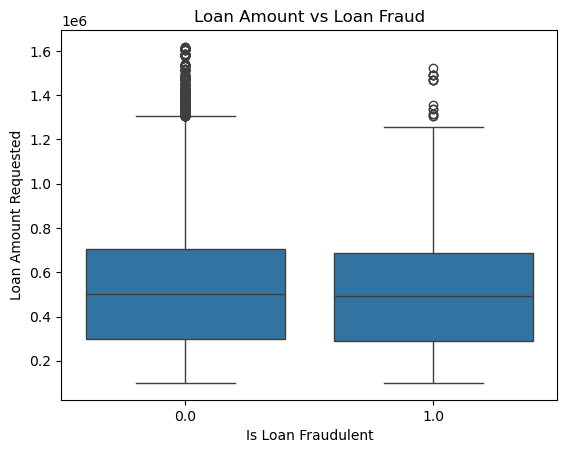

In [77]:
#Loan-Related Visualizations
# 8 Fraud vs Loan Amount

sns.boxplot(x='fraud_flag_y', y='loan_amount_requested', data=merged_df)
plt.title('Loan Amount vs Loan Fraud')
plt.xlabel('Is Loan Fraudulent')
plt.ylabel('Loan Amount Requested')
plt.show()



<h6>
The fig shows that there is not much difference that can be detected between the loan fraud and loan transaction. I think they are 
playing it safe by not letting the bank know the fraud as they request for the normal amount of money.
</h6>

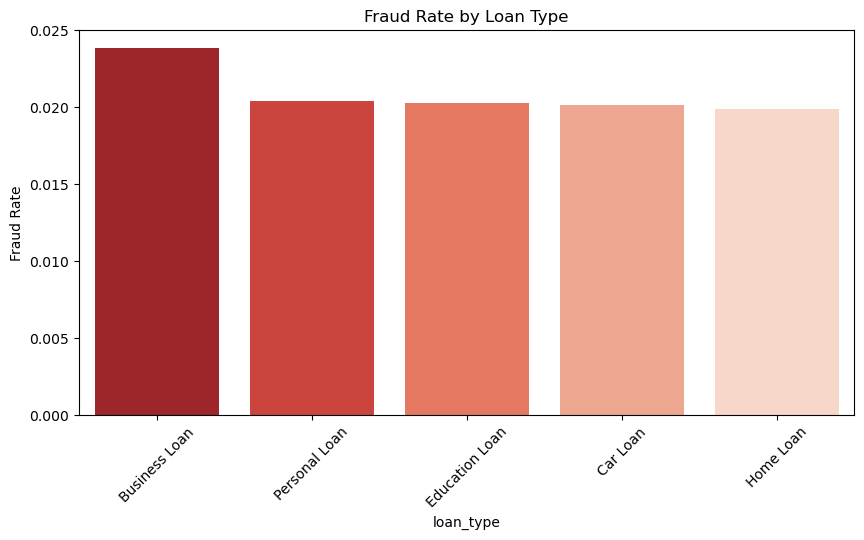

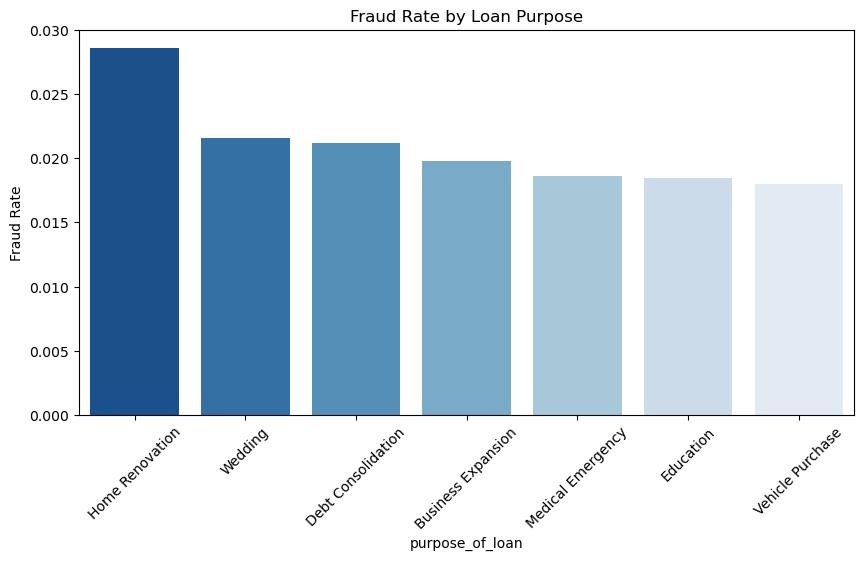

In [79]:
#9 Fraud by Loan Type or Purpose

plt.figure(figsize=(10,5))
fraud_rate = merged_df.groupby('loan_type')['fraud_flag_y'].mean().sort_values(ascending=False)
sns.barplot(x=fraud_rate.index, y=fraud_rate.values, palette='Reds_r')
plt.xticks(rotation=45)
plt.title('Fraud Rate by Loan Type')
plt.ylabel('Fraud Rate')
plt.show()

#10

plt.figure(figsize=(10,5))
fraud_rate = merged_df.groupby('purpose_of_loan')['fraud_flag_y'].mean().sort_values(ascending=False)
sns.barplot(x=fraud_rate.index, y=fraud_rate.values, palette='Blues_r')
plt.xticks(rotation=45)
plt.title('Fraud Rate by Loan Purpose')
plt.ylabel('Fraud Rate')
plt.show()



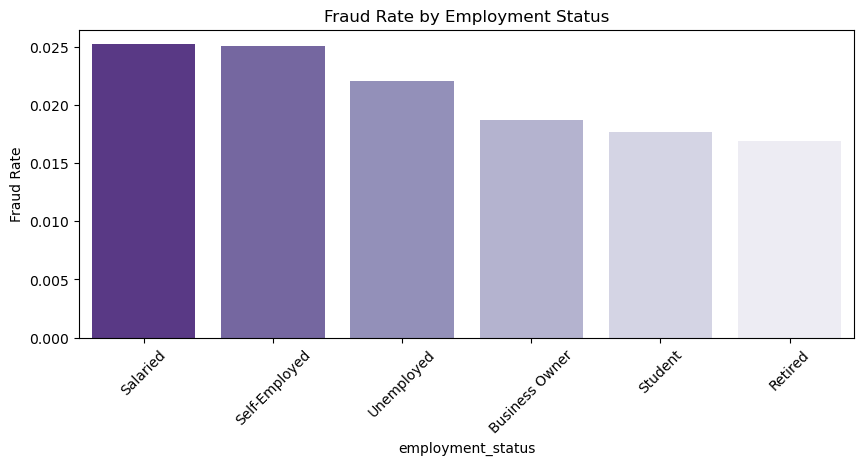

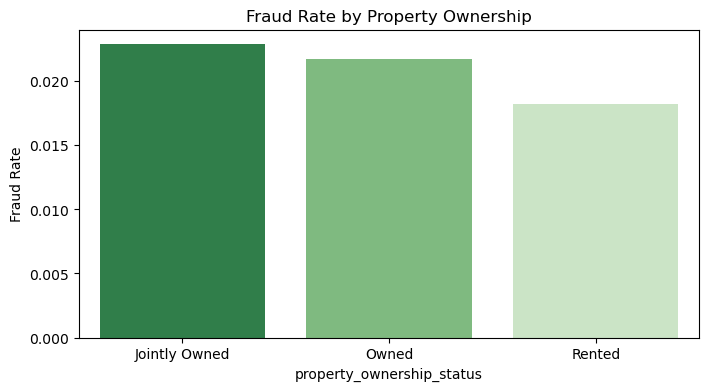

In [80]:
#11 Employment and Property Status

plt.figure(figsize=(10,4))
fraud_rate = merged_df.groupby('employment_status')['fraud_flag_y'].mean().sort_values(ascending=False)
sns.barplot(x=fraud_rate.index, y=fraud_rate.values, palette='Purples_r')
plt.xticks(rotation=45)
plt.title('Fraud Rate by Employment Status')
plt.ylabel('Fraud Rate')
plt.show()

#12

plt.figure(figsize=(8,4))
fraud_rate = merged_df.groupby('property_ownership_status')['fraud_flag_y'].mean().sort_values(ascending=False)
sns.barplot(x=fraud_rate.index, y=fraud_rate.values, palette='Greens_r')
plt.title('Fraud Rate by Property Ownership')
plt.ylabel('Fraud Rate')
plt.show()



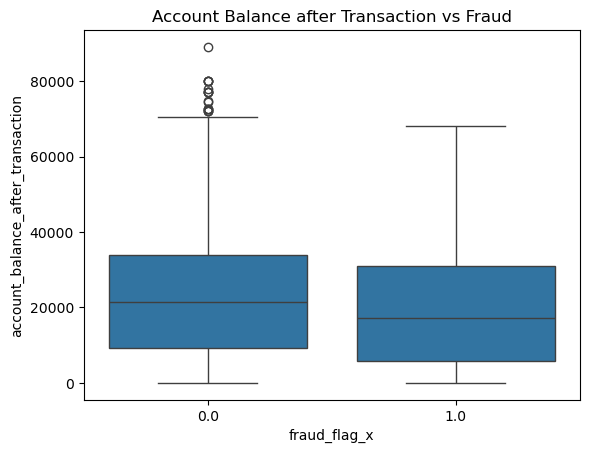

In [81]:
#13 Average Account Balance by Fraud Status

sns.boxplot(x='fraud_flag_x', y='account_balance_after_transaction', data=merged_df)
plt.title('Account Balance after Transaction vs Fraud')
plt.show()


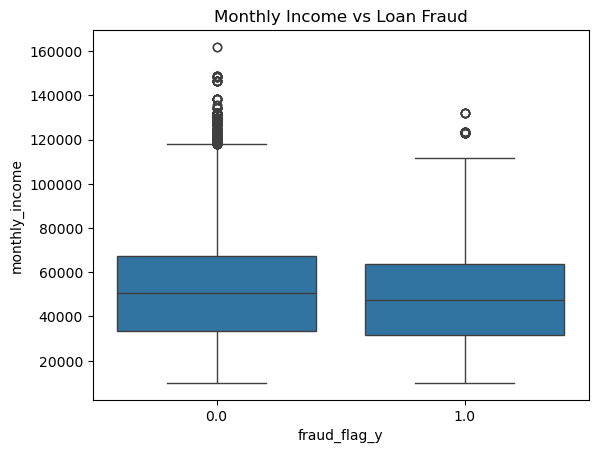

In [82]:
#14 Income vs Loan Fraud

sns.boxplot(x='fraud_flag_y', y='monthly_income', data=merged_df)
plt.title('Monthly Income vs Loan Fraud')
plt.show()

In [83]:

#from both the figures it can be concluded that tha account balance and the monthly income 
#of the fraudulent are not different from non-fradulent people

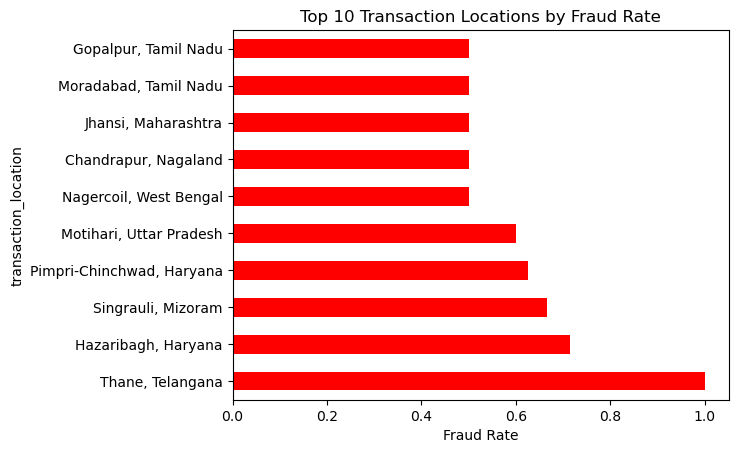

In [84]:
#15 Fraud by Location

top_locations = merged_df.groupby('transaction_location')['fraud_flag_x'].mean().sort_values(ascending=False).head(10)
top_locations.plot(kind='barh', color='red')
plt.title('Top 10 Transaction Locations by Fraud Rate')
plt.xlabel('Fraud Rate')
plt.show()


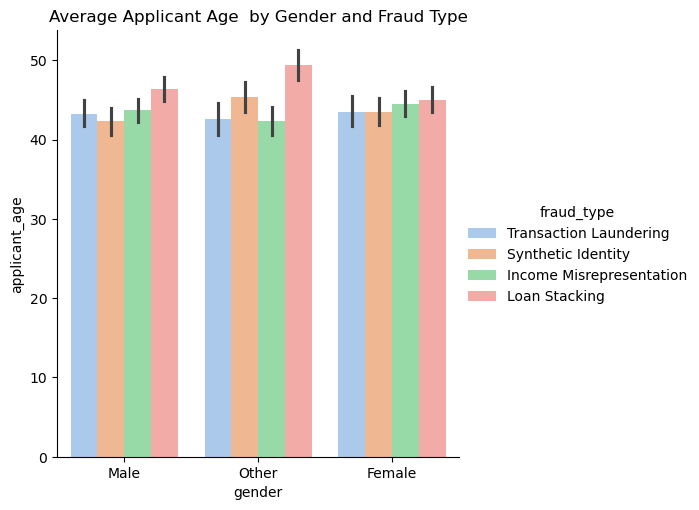

In [85]:
 #16  Average charges by sex and fraud
sns.catplot(data=merged_df, x='gender', y='applicant_age', hue='fraud_type', kind='bar', palette='pastel')
plt.title('Average Applicant Age  by Gender and Fraud Type')
plt.show()

In [86]:
# the fig shows that the average age group is between 40-50.

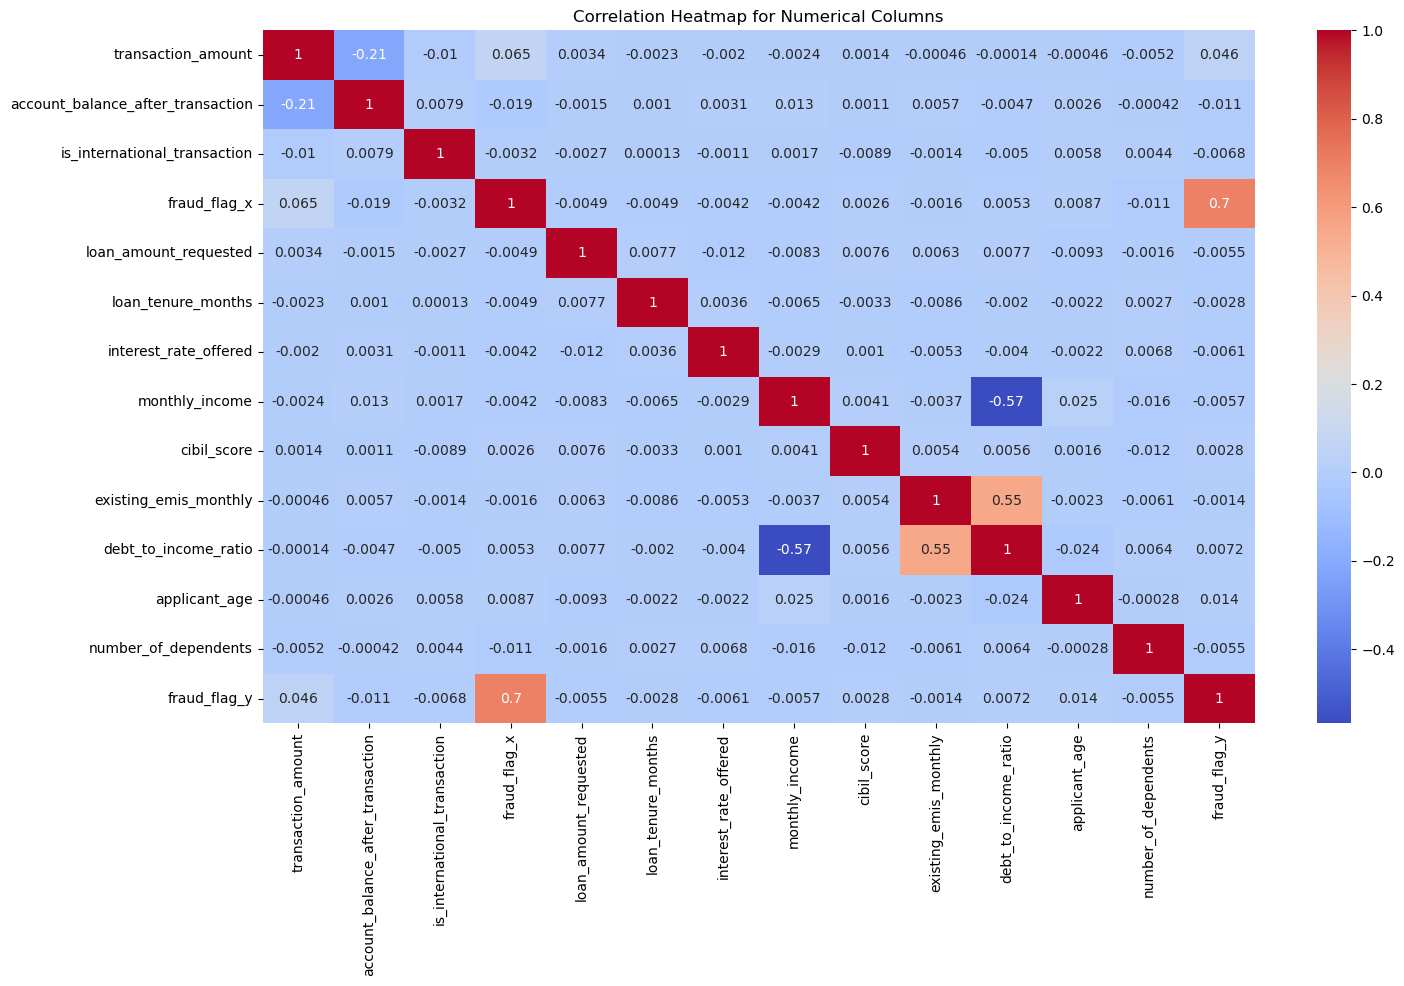

In [87]:
#17  Selecting only numerical columns
numerical_columns = merged_df.select_dtypes(include=['float64', 'int64']).columns

# Correlation Heatmap for Numerical Columns
plt.figure(figsize=(16, 9))
corr_matrix = merged_df[numerical_columns].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap for Numerical Columns')
plt.show()